In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

In [2]:
# Data processing
%run Data_processing.py

In [3]:
baseline = 'CurPol_OS_1.5C'
temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )

In [4]:
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in tqdm.tqdm(range(1,no_burn_years)):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

100%|██████████████████████████████████████| 165/165 [00:00<00:00, 40894.65it/s]


# $\Delta T_p \times \Delta T_s$

## Running simulations

In [5]:
T_peaks = np.arange(0,5.1,step=0.1) # change step to 0.2 for faster
T_oss = np.arange(0,3.1,step=0.1)

years = np.arange(2015,2301)
no_years=len(years)

D = np.zeros((len(T_peaks), len(T_oss), no_years, len(df_TEs)))
d_samps = np.zeros((len_sample,no_years,len(df_TEs)))
d_samps[:,0,:] = D_burn
# D[:,:,]
temps = np.ones((len(T_peaks), len(T_oss), no_years))
PAR = np.copy(popt)
for i in tqdm.tqdm(range(T_peaks.shape[0])):
    for j in range(T_oss.shape[0]): # T_os can only be less than T_peak
        # if T_oss[j] <= T_peaks[i]:
        PAR[1:3] = [T_peaks[i], T_oss[j]]
        temps[i,j,:] = OS_model(xdata,*PAR)
        D[i,j,0,:] = D_burn.mean(axis=0)
        for t in range(1,no_years):
            pc = q_c*temp_response(temps[i,j,t], T_lim, betas)
            pr = q_r*(1- temp_response(temps[i,j,t], T_lim, betas))
            for r in range(len_sample):
                d_samps[r,t,:] = environmental_update(d_samps[r,t-1,:], A[r],pc=pc,pr=pr)
        D[i,j,:,:] = d_samps.mean(axis=0)
                # D[i,j,t,:] = environmental_update(D[i,j,r,t-1,:], 
                #                                     A[r], 
                #                                     pc = pcs[i,j,t,:],
                #                                     pr = prs[i,j,t,:])

100%|███████████████████████████████████████████| 51/51 [57:59<00:00, 68.22s/it]


In [6]:
D_nr = np.delete(D,6,axis=-1)
AR_popt = np.array([k_risk(D_nr[:,:,-1,:],k,axis=2) 
                     for k in range(1,D_nr.shape[-1]+1)]) 

## Plotting

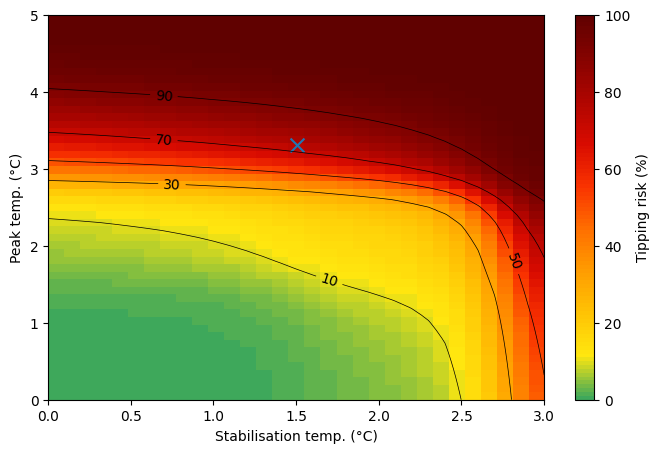

In [9]:
T_Pg,T_Og = np.meshgrid(T_peaks,T_oss)
fig,ax = plt.subplots(figsize=(8,5))

mask = np.zeros_like(T_Pg)#(T_Og>T_Pg)
to_plot = np.ma.array(AR_popt[0,:,:].transpose(),mask=mask)

colors_g = mpl.colormaps['Greens'](np.linspace(0, 1, 12))
colors_h = mpl.colormaps['cet_fire_r'](np.linspace(0, 1, 12))
c_offset = 1
c_list = [colors_g[7]] + [c_h for c_h in colors_h[c_offset:c_offset+9]]
cmap = LinearSegmentedColormap.from_list('my_cmap', c_list, N=100).with_extremes(bad='white')

ax.plot([0,0],[3,3],color='k')
ax.scatter(popt[2],popt[1],marker='x',s=100)
# im=ax.imshow(to_plot*100,cmap=cmap,#cmap='Reds',
#               extent=(T_peaks[0], T_peaks[-1], T_oss[0], T_oss[-1]),
#               origin='lower',vmin=0,vmax=100,zorder=0)
im=ax.imshow(to_plot.T*100,cmap=cmap,#cmap='Reds',
              extent=(T_oss[0], T_oss[-1],T_peaks[0], T_peaks[-1]),
              origin='lower',vmin=0,vmax=100,zorder=0,aspect='auto')
fig.colorbar(im,ax=ax,label='Tipping risk (%)')
CS = ax.contour(T_Og.T,T_Pg.T, to_plot.T*100,[10,30,50,70,90],
                 corner_mask=True,colors=['k'],linewidths=0.5)
ax.clabel(CS)
# plt.clabel(CS)
ax.set_ylabel('Peak temp. (°C)')
ax.set_xlabel('Stabilisation temp. (°C)')
# ax.set_title('Aggregate risk heatmap for %s scenario'%baseline)
# plt.colorbar(im)

fig.savefig('../../../Figures/Overshoots/NCC/2d_%s_TpTs.png'%baseline,bbox_inches='tight')